Newtons method

We know what newton's method do right? or read page 50 in the note book everything written on it.

In [10]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
#2d

def f(x,y):
    return 3*x**2 + 2*x*y + 2*y**2 - 4*x - 6*y

def gradient(x,y):
    df_dx = 6*x + 2*y - 4
    df_dy = 2*x + 4*y - 6
    return np.array([df_dx, df_dy])

def hessian():
    d2f_dx2 = 6
    d2f_dy2 = 4
    d2f_dxdy= 2
    d2f_dydx= 2
    return np.array([[d2f_dx2, d2f_dxdy],
                    [d2f_dydx, d2f_dy2]])


In [12]:
tol = 1e-6
k = 0
max_iter = 100
alpha = 1 #as pure newtons method always alpha = 1

point = np.array([10,-5])

In [13]:
history_of_x = [point[0]]
history_of_y = [point[1]]
history_of_z = [f(point[0], point[1])]

In [14]:
while np.linalg.norm(gradient(point[0], point[1]))> tol and max_iter > k :

    #direction
    direction = - np.dot(np.linalg.inv(hessian()) , gradient(point[0], point[1]))

    #new point:
    new_pos = point + direction

    #update:
    point = new_pos

    #epoch:
    k +=1

    #store:
    history_of_x.append(point[0])
    history_of_y.append(point[1])
    history_of_z.append(f(point[0], point[1]))

    print(f'[Epoch {k}]: Current Height: {f(point[0], point[1])}, Current Points: {point}')


[Epoch 1]: Current Height: -4.6000000000000005, Current Points: [0.2 1.4]


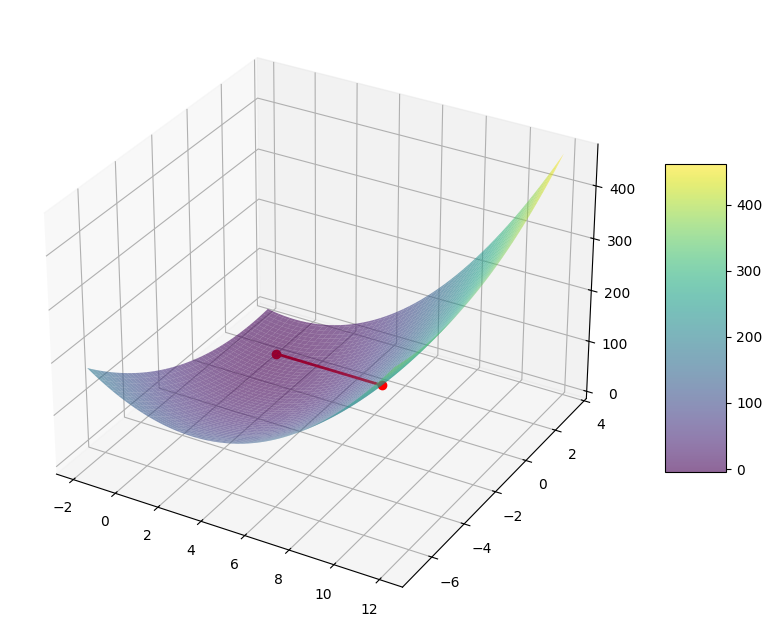

In [15]:
#plotting:

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

X_surf = np.linspace(min(history_of_x)-2, max(history_of_x)+2,100)
Y_surf = np.linspace(min(history_of_y)-2, max(history_of_y)+2,100)
X,Y = np.meshgrid(X_surf, Y_surf)
Z = f(X,Y)

surf = ax.plot_surface(X,Y,Z,cmap='viridis', alpha=0.6) #the 3d land
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5)

ax.plot(history_of_x,history_of_y,history_of_z, color = 'Red', marker='o', linewidth = 2,label='AGD Path') #add a marker if want

plt.show()

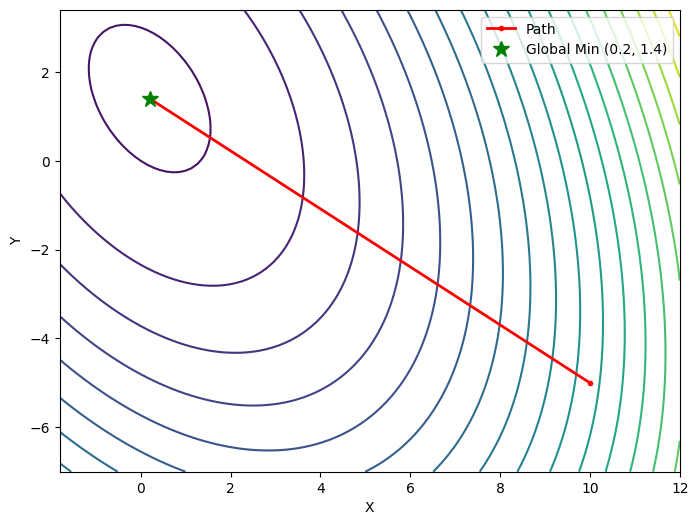

In [21]:
fig,ax = plt.subplots(figsize = (8,6))
cp = ax.contour(X,Y,Z, levels=20,cmap='viridis')
ax.plot(history_of_x, history_of_y, 'ro-', linewidth=2, markersize=3, label='Path')
ax.plot(0.2, 1.4, 'g*', markersize=12, label='Global Min (0.2, 1.4)')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.legend()
plt.show()